# Qué se pierde al resumir una oración en un vector

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e IA, IFTS N.º 24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---

| | |
|---|---|
| **Problema** | Un buscador compara frases, no palabras, y convertir una oración en un vector descarta algo. |
| **Producto** | Una función de promedio sin palabras vacías, una de embedding de oración, tres pares propios comparados con tres métodos y una decisión. |
| **Recursos** | Word2Vec (unos 2 GB) y un modelo de oraciones (unos 470 MB, se descarga la primera vez). Con poca memoria, `LIMITE_DE_PALABRAS = 200000`. |

«El perro mordió al hombre» y «El hombre mordió al perro» usan las mismas palabras y cuentan historias opuestas. «Me gustó mucho la película» y «No me gustó nada la película» comparten casi todo y significan lo contrario. Para comparar textos hay que convertirlos en vectores, y esa conversión borra distinciones. Probamos tres maneras, cada una propuesta para arreglar una falla de la anterior: **contar palabras**, **promediar vectores de palabras** y **calcular un embedding de oración**.

**¿Qué distinciones sobreviven cuando una oración se resume en un único vector y cuáles desaparecen sin aviso?**

> **Cómo se trabaja.** Explorás cada método con el código ya escrito y las notas **Para mirar**. Al final de cada bloque, un **microlaboratorio** te dice qué líneas completar y con qué; la celda siguiente comprueba.

In [1]:
import re
import sys
import time
import importlib.metadata

import numpy as np
import pandas as pd
from IPython.display import display

from gensim.models import KeyedVectors
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer

import utils

# None carga todo Word2Vec. Con poca memoria, proba con 200000.
LIMITE_DE_PALABRAS = None

pd.set_option("display.max_colwidth", 100)

# Este cuaderno no usa azar: los modelos ya estan entrenados.
print("Python:", sys.version.split()[0])
paquetes = ["gensim", "sentence-transformers", "scikit-learn", "numpy"]
for paquete in paquetes:
    print(f"{paquete}: {importlib.metadata.version(paquete)}")
print("Limite de palabras:", LIMITE_DE_PALABRAS)

W1019 15:06:40.641000 13004 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Python: 3.12.13
gensim: 4.4.0
sentence-transformers: 6.1.0
scikit-learn: 1.9.1
numpy: 2.5.4
Limite de palabras: None


## 1. Doce pares, un cambio por vez

Para saber qué pierde cada método necesitamos pares de oraciones que difieran en **una sola cosa**. Las 12 parejas **las inventamos nosotros**: no son textos reales ni sirven como evidencia sobre el español, y con uno o dos pares por categoría solo podemos *mostrar* un comportamiento, no medir su frecuencia.

| Categoría | Qué cambia | Qué esperaríamos de una buena representación |
|---|---|---|
| orden | mismas palabras, otro orden | oraciones distintas |
| negación | aparece *no* | significado contrario |
| paráfrasis | otras palabras, mismo significado | muy cercanas |
| polisemia | misma palabra, otro sentido | más lejanas si el sentido cambia |
| entidad | cambia un nombre propio | cercanas, no idénticas |
| tema | mismo campo, otra cosa | cercanía moderada |
| sin relación | nada en común | lejanas |

In [2]:
# Datos construidos para este cuaderno: no provienen de ningun texto real.
pares_de_oraciones = [
    {"categoria": "orden",
     "a": "El perro mordió al hombre", "b": "El hombre mordió al perro"},
    {"categoria": "orden",
     "a": "Ana le prestó el libro a Luis",
     "b": "Luis le prestó el libro a Ana"},
    {"categoria": "negacion",
     "a": "Me gustó mucho la película",
     "b": "No me gustó nada la película"},
    {"categoria": "negacion",
     "a": "El tren llega a las ocho", "b": "El tren no llega a las ocho"},
    {"categoria": "parafrasis",
     "a": "El tren llega a las ocho", "b": "El convoy arriba a las ocho"},
    {"categoria": "polisemia, otro sentido",
     "a": "Deposité la plata en el banco",
     "b": "El banco de la plaza está pintado"},
    {"categoria": "polisemia, mismo sentido",
     "a": "Deposité la plata en el banco", "b": "Retiré la plata del banco"},
    {"categoria": "tema sin equivalencia",
     "a": "La final del mundial se juega el domingo",
     "b": "El árbitro expulsó al delantero"},
    {"categoria": "entidad",
     "a": "Messi llegó a Rosario", "b": "Maradona llegó a Rosario"},
    {"categoria": "entidad (lugar)",
     "a": "Viajé a Rosario en micro", "b": "Viajé a Córdoba en micro"},
    {"categoria": "tema cercano",
     "a": "Hoy cocino milanesas con puré",
     "b": "Mañana hago asado con ensalada"},
    {"categoria": "sin relacion",
     "a": "El tren llega a las ocho",
     "b": "Las plantas del desierto necesitan poca agua"},
]
print(len(pares_de_oraciones), "pares construidos")

12 pares construidos


## 2. Primer método: contar palabras

Es la bolsa de palabras del cuaderno 01. Cada par se vectoriza por separado: el vocabulario son las palabras de las dos oraciones, y el coseno mide cuánto se solapan.

In [3]:
def coseno_por_conteo(oracion_a: str, oracion_b: str) -> float:
    """Calcula el coseno entre los conteos de palabras de dos oraciones.

    Args:
        oracion_a: Primera oracion.
        oracion_b: Segunda oracion.

    Returns:
        El coseno, entre 0 y 1 (los conteos no son negativos).
    """
    vectorizador = CountVectorizer(token_pattern=utils.PATRON_DE_PALABRA)
    conteos = vectorizador.fit_transform(
        raw_documents=[oracion_a, oracion_b]
    ).toarray()
    return utils.coseno(conteos[0], conteos[1])


cosenos_por_conteo = []
for par in pares_de_oraciones:
    cosenos_por_conteo.append(coseno_por_conteo(par["a"], par["b"]))

tabla = pd.DataFrame(pares_de_oraciones)
tabla["conteo"] = np.round(cosenos_por_conteo, 3)
display(tabla[["categoria", "conteo"]])

,categoria,conteo
0,orden,1.000
1,orden,1.000
2,negacion,0.730
3,negacion,0.926
4,parafrasis,0.667
5,"polisemia, otro sentido",0.463
6,"polisemia, mismo sentido",0.548
7,tema sin equivalencia,0.158
8,entidad,0.750
9,entidad (lugar),0.800


> **Para mirar.**
>
> - los dos pares de *orden* dan 1,000 (mismas palabras, mismo vector). La *negación* apenas mueve el número (0,73 y 0,93). La paráfrasis *tren/convoy* da solo 0,67 aunque el significado es el mismo: para el conteo, *tren* y *convoy* son columnas sin relación.
> - los vectores de palabras corrigen lo segundo: *tren* y *convoy* tienen vectores cercanos. ¿Cómo se obtiene un vector de oración a partir de ellos?

## 3. Segundo método: promediar los vectores de las palabras

Se busca el vector Word2Vec de cada palabra y se promedian. **Cada oración se promedia por separado**: un error frecuente es promediar una lista compartida y obtener el mismo vector para todas. Usamos los vectores del cuaderno 02 (SBW, 2016, textos institucionales y enciclopédicos).

In [4]:
inicio_de_la_carga = time.perf_counter()
vectores_word2vec = utils.cargar_vectores_word2vec(limite=LIMITE_DE_PALABRAS)
segundos = time.perf_counter() - inicio_de_la_carga
print(f"Word2Vec: {len(vectores_word2vec.key_to_index):,} palabras, "
      f"{vectores_word2vec.vector_size} dimensiones | carga: {segundos:.0f} s")

# Paso a paso con una oracion.
oracion = "Deposité la plata en el banco"
palabras = utils.separar_palabras(oracion)
promedio, sin_cobertura = utils.promedio_de_vectores(
    palabras, vectores_word2vec
)
print("Palabras:", palabras)
print("Palabras sin vector:", sin_cobertura)
print("Dimensiones del promedio:", promedio.shape)

# Un promedio no depende del orden: las mismas palabras dan el mismo vector.
primera = pares_de_oraciones[0]
promedio_a, _ = utils.promedio_de_vectores(
    utils.separar_palabras(primera["a"]), vectores_word2vec
)
promedio_b, _ = utils.promedio_de_vectores(
    utils.separar_palabras(primera["b"]), vectores_word2vec
)
assert np.allclose(promedio_a, promedio_b), "Deberian ser el mismo vector."
print("perro/hombre: los dos promedios son el mismo vector.")

Word2Vec: 1,692,025 palabras, 300 dimensiones | carga: 9 s
Palabras: ['deposité', 'la', 'plata', 'en', 'el', 'banco']
Palabras sin vector: []
Dimensiones del promedio: (300,)
perro/hombre: los dos promedios son el mismo vector.


> **Para mirar.** cada palabra aporta un vector de 300 números y el promedio es otro vector de 300. Como un promedio no tiene orden, *El perro mordió al hombre* y *El hombre mordió al perro* dan **exactamente** el mismo vector.

In [5]:
def coseno_por_promedio(oracion_a: str, oracion_b: str) -> tuple:
    """Calcula el coseno entre los promedios de vectores de dos oraciones.

    Args:
        oracion_a: Primera oracion.
        oracion_b: Segunda oracion.

    Returns:
        Una tupla (coseno, sin_vector): el coseno (nan si alguna oracion
        quedo sin ningun vector) y las palabras sin vector.
    """
    promedio_a, sin_vector_a = utils.promedio_de_vectores(
        utils.separar_palabras(oracion_a), vectores_word2vec
    )
    promedio_b, sin_vector_b = utils.promedio_de_vectores(
        utils.separar_palabras(oracion_b), vectores_word2vec
    )
    return utils.coseno(promedio_a, promedio_b), sin_vector_a + sin_vector_b


cosenos_por_promedio = []
palabras_sin_vector = []
for par in pares_de_oraciones:
    coseno_del_par, faltantes = coseno_por_promedio(par["a"], par["b"])
    cosenos_por_promedio.append(coseno_del_par)
    palabras_sin_vector.append(", ".join(faltantes))

tabla["promedio"] = np.round(cosenos_por_promedio, 3)
tabla["sin vector"] = palabras_sin_vector
display(tabla[["categoria", "conteo", "promedio", "sin vector"]])

,categoria,conteo,promedio,sin vector
0,orden,1.000,1.000,"al, al"
1,orden,1.000,1.000,
2,negacion,0.730,0.961,
3,negacion,0.926,0.985,"ocho, ocho"
4,parafrasis,0.667,0.895,"ocho, ocho"
5,"polisemia, otro sentido",0.463,0.870,
6,"polisemia, mismo sentido",0.548,0.887,del
7,tema sin equivalencia,0.158,0.564,"del, domingo, al"
8,entidad,0.750,0.978,maradona
9,entidad (lugar),0.800,0.892,


> **Para mirar.**
>
> - el promedio arregla la paráfrasis: *tren/convoy* sube de 0,67 a 0,90.
> - pero **todo sube**: el par *sin relación* da 0,63 y *tema cercano* (milanesas y asado), 0,85. Las palabras muy frecuentes (*el*, *la*, *en*) tienen vectores parecidos y pesan igual que las demás.
> - sigue sin ver el orden (1,000) ni la negación (0,96 y 0,99).
> - la columna `sin vector` muestra palabras que el promedio **ignora en silencio**: *al*, *del*, *ocho*, *domingo* y *maradona*.

In [6]:
# Misma regla de palabras, pero sin pasar a minusculas: asi Maradona
# conserva su mayuscula, como esta en el vocabulario del modelo.
patron = r"[A-Za-z\u00e1\u00e9\u00ed\u00f3\u00fa\u00fc\u00f1]+"
con_messi = re.findall(patron, "Messi llegó a Rosario")
con_maradona = re.findall(patron, "Maradona llegó a Rosario")
promedio_messi, faltan_1 = utils.promedio_de_vectores(
    con_messi, vectores_word2vec
)
promedio_maradona, faltan_2 = utils.promedio_de_vectores(
    con_maradona, vectores_word2vec
)

par_de_entidad = pares_de_oraciones[8]
assert par_de_entidad["a"].startswith("Messi"), "El par 8 es Messi/Maradona."
coseno_con_mayusculas = utils.coseno(promedio_messi, promedio_maradona)
print("Sin vector con mayusculas:", faltan_1, faltan_2)
print(f"Coseno con mayusculas: {coseno_con_mayusculas:.3f}")
print(f"Coseno pasando todo a minuscula: {cosenos_por_promedio[8]:.3f}")

Sin vector con mayusculas: [] []
Coseno con mayusculas: 0.943
Coseno pasando todo a minuscula: 0.978


> **Para mirar.** con mayúsculas, *Maradona* entra en el promedio y el coseno baja de 0,98 a 0,94. Una decisión de preprocesamiento (pasar a minúscula) cambió un resultado sin que la tabla avisara. Por eso importa mirar las palabras sin cobertura.

### Microlaboratorio 1 — Promedio sin palabras vacías

**Tarea.** Probar una hipótesis: si todo sube porque las palabras frecuentes pesan igual que las demás, sacarlas debería separar mejor los pares.  
**Producto.** `coseno_por_promedio_sin_vacias`, comprobada, y la comparación de los 12 pares con y sin palabras vacías.  
**Antes de empezar.** Secciones 2 y 3.

Completá las líneas marcadas `COMPLETAR`:

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `con_contenido` | las palabras de la oración que **no** son vacías | un bucle que recorre `palabras` y agrega a la lista solo las que no están en `palabras_vacias` (`if palabra not in ...`) |
| (2) `promedio` | el promedio de las palabras con contenido | `utils.promedio_de_vectores` con dos argumentos: la lista y `vectores_word2vec`; devuelve dos valores, nos quedamos con el primero |
| (3) `coseno` | el coseno entre los dos promedios | `utils.coseno` con los dos promedios |

**Comprobación.** con las palabras vacías afuera, el par *sin relación* tiene que dar un coseno **menor** que el 0,63 de la tabla, y los dos pares de *orden* siguen dando 1.

> **Ayuda 1.** La lista de palabras vacías es la misma del cuaderno 01 (`datos/stopwords_es.txt`, ya cargada abajo).  
> **Ayuda 2.** Es la misma cuenta de `coseno_por_promedio`, pero filtrando antes de promediar.

In [7]:
with open("datos/stopwords_es.txt", encoding="utf-8") as archivo:
    palabras_vacias = archivo.read().split()
print(f"{len(palabras_vacias)} palabras vacias. Primeras:",
      palabras_vacias[:5])

260 palabras vacias. Primeras: ['a', 'al', 'algo', 'algunas', 'algunos']


In [8]:
def coseno_por_promedio_sin_vacias(oracion_a: str, oracion_b: str) -> float:
    """Calcula el coseno entre promedios, sin contar las palabras vacias.

    Args:
        oracion_a: Primera oracion.
        oracion_b: Segunda oracion.

    Returns:
        El coseno entre los dos promedios.
    """
    promedios = []
    for oracion in [oracion_a, oracion_b]:
        palabras = utils.separar_palabras(oracion)
        con_contenido = palabras  # COMPLETAR (1)
        promedio = None  # COMPLETAR (2)
        promedios.append(promedio)
    coseno = 0.0  # COMPLETAR (3)
    return coseno


con_vacias = []
sin_vacias = []
for par in pares_de_oraciones:
    con_vacias.append(coseno_por_promedio(par["a"], par["b"])[0])
    sin_vacias.append(coseno_por_promedio_sin_vacias(par["a"], par["b"]))

utils.comprobar(
    sin_vacias[11] < con_vacias[11] and abs(sin_vacias[0] - 1) < 1e-6,
    "revisa (1), (2) y (3): sin relacion debe bajar de 0.63 y orden "
    "seguir en 1",
)
comparacion = pd.DataFrame({
    "categoria": tabla["categoria"],
    "con vacias": np.round(con_vacias, 3),
    "sin vacias": np.round(sin_vacias, 3),
})
display(comparacion)

Todavia falta. Pista: revisa (1), (2) y (3): sin relacion debe bajar de 0.63 y orden seguir en 1


,categoria,con vacias,sin vacias
0,orden,1.000,0.0
1,orden,1.000,0.0
2,negacion,0.961,0.0
3,negacion,0.985,0.0
4,parafrasis,0.895,0.0
5,"polisemia, otro sentido",0.870,0.0
6,"polisemia, mismo sentido",0.887,0.0
7,tema sin equivalencia,0.564,0.0
8,entidad,0.978,0.0
9,entidad (lugar),0.892,0.0


**Para pensar:** ¿bajó el coseno de los pares *sin relación* y *tema cercano*? ¿Qué pasó con *orden* y *negación*? Quitar palabras vacías mejora la separación de temas, pero no puede devolver lo que un promedio no tiene: el orden.

## 4. Tercer método: un vector para toda la oración

Los modelos de oraciones (*sentence embeddings*) leen la oración completa con una red y producen un vector por oración. Se usan en buscadores semánticos y en la recuperación para modelos de lenguaje. Que lean la oración completa no implica que «entiendan». Su ficha:

| Campo | Contenido |
|---|---|
| Modelo | `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2` |
| Tamaño | 117,7 millones de parámetros; vectores de 384 dimensiones |
| Idiomas | multilingüe, unos 50, incluye español |
| Longitud máxima | **128 tokens**; lo que sigue se descarta |
| Pooling | promedio de los vectores de los tokens (*mean pooling*) |
| Licencia | Apache 2.0 |
| No verificamos | con qué datos se entrenó ni su rendimiento en español rioplatense |

In [9]:
inicio_de_la_carga = time.perf_counter()
modelo_de_oraciones = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)
segundos = time.perf_counter() - inicio_de_la_carga
print(f"Dimensiones: {modelo_de_oraciones.get_sentence_embedding_dimension()}"
      f" | longitud maxima: {modelo_de_oraciones.max_seq_length} tokens"
      f" | carga: {segundos:.0f} s")

# Un token es la pieza que el modelo procesa (una palabra o un pedazo).
# El modelo da un vector por token, DENTRO de la oracion: por eso el vector
# de "banco" cambia segun la oracion.
oraciones_con_banco = [
    "Deposité la plata en el banco",
    "Retiré la plata del banco",
    "El banco de la plaza está pintado",
]
vectores_de_banco = []
for oracion in oraciones_con_banco:
    ids = modelo_de_oraciones.tokenizer(oracion)["input_ids"]
    tokens = modelo_de_oraciones.tokenizer.convert_ids_to_tokens(ids)
    por_token = modelo_de_oraciones.encode(
        oracion, output_value="token_embeddings", convert_to_tensor=True
    ).cpu().numpy()
    vectores_de_banco.append(por_token[tokens.index("▁banco")])

    # El vector de la oracion es el promedio de los vectores de sus tokens.
    de_la_oracion = modelo_de_oraciones.encode(oracion)
    assert np.allclose(por_token.mean(axis=0), de_la_oracion, atol=1e-4)

financiero = utils.coseno(vectores_de_banco[0], vectores_de_banco[1])
de_plaza = utils.coseno(vectores_de_banco[0], vectores_de_banco[2])
print(f"banco financiero vs financiero: {financiero:.3f}")
print(f"banco financiero vs de plaza: {de_plaza:.3f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 11176.57it/s]

/var/folders/6v/v8qk6d1n0wgffql57pntwypw0000gn/T/ipykernel_13004/2886915163.py:6: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"Dimensiones: {modelo_de_oraciones.get_sentence_embedding_dimension()}"


Dimensiones: 384 | longitud maxima: 128 tokens | carga: 5 s


banco financiero vs financiero: 0.974
banco financiero vs de plaza: 0.798


> **Para mirar.**
>
> - el vector de *banco* cambia según la oración: dos usos financieros se parecen más entre sí (0,97) que con el *banco* de la plaza (0,80). Con Word2Vec daría exactamente 1,0.
> - la aserción confirma el mecanismo: un embedding de oración es el **promedio de vectores contextuales**. La diferencia con el segundo método no está en promediar, sino en *qué* se promedia.
> - son tres oraciones: no alcanza para afirmar que el modelo «desambigua» de manera sistemática.

,categoria,conteo,promedio,oracion
0,orden,1.000,1.000,0.978
1,orden,1.000,1.000,0.990
2,negacion,0.730,0.961,0.470
3,negacion,0.926,0.985,0.843
4,parafrasis,0.667,0.895,0.636
5,"polisemia, otro sentido",0.463,0.870,0.335
6,"polisemia, mismo sentido",0.548,0.887,0.860
7,tema sin equivalencia,0.158,0.564,0.142
8,entidad,0.750,0.978,0.712
9,entidad (lugar),0.800,0.892,0.775


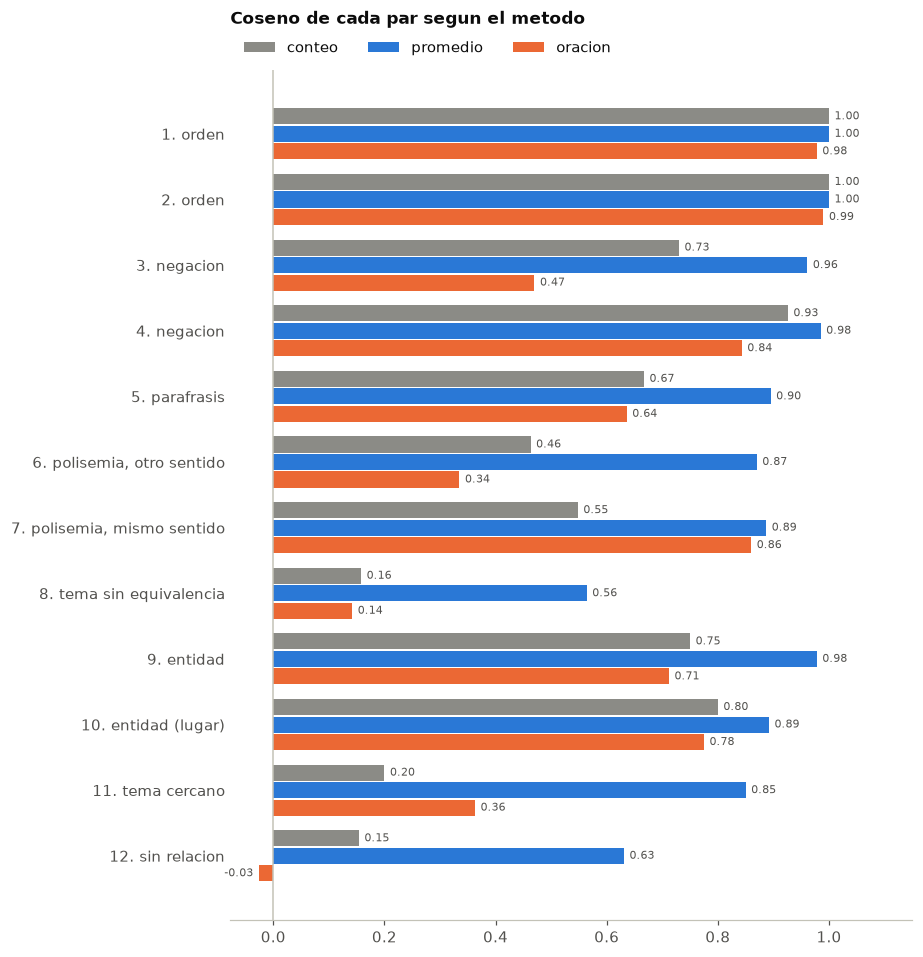

In [10]:
# Codificamos todas las oraciones juntas y luego medimos cada par.
todas = []
for par in pares_de_oraciones:
    todas.append(par["a"])
    todas.append(par["b"])
vectores_de_oraciones = modelo_de_oraciones.encode(todas)

cosenos_por_oracion = []
lugar = 0
for par in pares_de_oraciones:
    coseno_del_par = utils.coseno(
        vectores_de_oraciones[lugar], vectores_de_oraciones[lugar + 1]
    )
    cosenos_por_oracion.append(coseno_del_par)
    lugar += 2

tabla["oracion"] = np.round(cosenos_por_oracion, 3)
display(tabla[["categoria", "conteo", "promedio", "oracion"]])

# Los tres metodos, par por par.
etiquetas = []
numero = 1
for categoria in tabla["categoria"]:
    etiquetas.append(f"{numero}. {categoria}")
    numero += 1
utils.dibujar_barras_agrupadas(
    etiquetas,
    {
        "conteo": list(tabla["conteo"]),
        "promedio": list(tabla["promedio"]),
        "oracion": list(tabla["oracion"]),
    },
    titulo="Coseno de cada par segun el metodo",
    maximo=1.15,
)

> **Para mirar.**
>
> - **mejoró:** separa *polisemia, otro sentido* (0,34) de *mismo sentido* (0,86), y *sin relación* baja a −0,03, el valor más bajo de las tres columnas. (Un coseno cerca de 0 significa vectores casi perpendiculares, no «opuestos».)
> - **no mejoró:** *orden* da 0,98 y 0,99; la *negación* depende del par (0,47 contra 0,84); *tren/convoy* da 0,64, por debajo del conteo. Con uno o dos pares por categoría solo podemos decir que **en estos pares** pasó eso.

**Lo que el modelo ni siquiera lee.** Lee hasta 128 tokens y **descarta el final sin avisar**. ¿Cuántos fragmentos literarios del curso lo superan?

In [11]:
fragmentos = utils.cargar_fragmentos()

largos = []
for texto in fragmentos["texto"]:
    ids = modelo_de_oraciones.tokenizer(texto)["input_ids"]
    largos.append(len(ids))
fragmentos["tokens"] = largos

limite = modelo_de_oraciones.max_seq_length
excedidos = fragmentos[fragmentos["tokens"] > limite]
print(f"Tokens por fragmento: mediana {int(fragmentos['tokens'].median())}"
      f", maximo {fragmentos['tokens'].max()}")
print(f"Fragmentos que superan {limite} tokens: "
      f"{len(excedidos)} de {len(fragmentos)}")

# Que ve el modelo del fragmento mas largo: solo los primeros 128 tokens.
mas_largo = fragmentos.sort_values("tokens", ascending=False).iloc[0]
ids = modelo_de_oraciones.tokenizer(mas_largo["texto"])["input_ids"]
lo_que_ve = modelo_de_oraciones.tokenizer.decode(
    ids[:limite], skip_special_tokens=True
)
print("Termina de leer en: ...", lo_que_ve[-100:])
print("Descarta:", mas_largo["texto"][len(lo_que_ve):][:100], "...")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (137 > 128). Running this sequence through the model will result in indexing errors


Tokens por fragmento: mediana 86, maximo 174


Fragmentos que superan 128 tokens: 10 de 137
Termina de leer en: ... ria recogía esos gestos como heroicos, tanto la Historia que recogía los gestos del uno, como la que
Descarta:  recogía los gestos del otro, ya que cada lado escribía su propia Historia; así, Wellington era un h ...


> **Para mirar.** 10 de los 137 fragmentos superan el límite. Si lo importante está al final, el embedding no lo refleja. Para comparar con justicia hay que declarar que este método trabaja con el texto truncado y los otros no.

### Microlaboratorio 2 — Tus tres pares

**Tarea.** Medir tres pares propios con los tres métodos y decidir cuál usarías.  
**Producto.** Una tabla con los tres métodos para tus pares y una decisión escrita.  
**Antes de empezar.** Secciones 2 a 4.

Completá las líneas marcadas `COMPLETAR`:

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `vectores_de_oraciones` | los vectores de las dos oraciones | el método `modelo_de_oraciones.encode` con **una lista** que contiene `oracion_a` y `oracion_b` |
| (2) `coseno` | el coseno entre los dos vectores | `utils.coseno` con `vectores_de_oraciones[0]` y `vectores_de_oraciones[1]` |
| (3) `cantidad` | cuántos tokens tiene el texto | `len` aplicado a la lista `ids` (ya calculada en la línea de arriba) |
| Paso 2 `mis_pares` | tres pares propios | una negación sutil, una expresión rioplatense, una ironía o una frase con dos sentidos |
| Paso 3 `mi_decision` | una o dos oraciones | qué método usarías para el sistema que tenés en mente y qué error tendrías que tolerar |

**Comprobación.** `coseno_por_oracion` debe dar unos 0,98 para el par de *orden* (perro/hombre) y `largo_en_tokens` debe dar 9 para «Deposité la plata en el banco».

> **Ayuda 1.** Es lo mismo que hiciste con `modelo_de_oraciones` en la sección 4, pero para un solo par.  
> **Ayuda 2.** Los 9 tokens incluyen los dos tokens especiales de inicio y fin.

In [12]:
def coseno_por_oracion(oracion_a: str, oracion_b: str) -> float:
    """Calcula el coseno entre los embeddings de dos oraciones.

    Args:
        oracion_a: Primera oracion.
        oracion_b: Segunda oracion.

    Returns:
        El coseno entre los dos vectores.
    """
    vectores_de_oraciones = []  # COMPLETAR (1)
    coseno = 0.0  # COMPLETAR (2)
    return coseno


def largo_en_tokens(texto: str) -> int:
    """Cuenta los tokens que el modelo de oraciones ve en un texto.

    Args:
        texto: El texto a medir.

    Returns:
        Cantidad de tokens, con los especiales de inicio y fin.
    """
    ids = modelo_de_oraciones.tokenizer(texto)["input_ids"]
    cantidad = 0  # COMPLETAR (3)
    return cantidad


perro = coseno_por_oracion(
    "El perro mordió al hombre", "El hombre mordió al perro"
)
utils.comprobar(
    abs(perro - 0.978) < 0.01
    and largo_en_tokens("Deposité la plata en el banco") == 9,
    "revisa (1), (2) y (3): perro/hombre debe dar 0.98 y banco debe dar 9",
)

# PASO 2: cambia estos tres pares por los tuyos.
mis_pares = [
    {"a": "Qué bien, otra vez lloviendo en el picnic",
     "b": "Qué mal que llueva otra vez en el picnic"},
    {"a": "Ese pibe labura mucho", "b": "Ese muchacho trabaja mucho"},
    {"a": "Llegaron tarde", "b": "No llegaron temprano"},
]
filas = []
for par in mis_pares:
    filas.append({
        "a": par["a"],
        "b": par["b"],
        "conteo": round(coseno_por_conteo(par["a"], par["b"]), 3),
        "promedio": round(coseno_por_promedio(par["a"], par["b"])[0], 3),
        "oracion": round(coseno_por_oracion(par["a"], par["b"]), 3),
    })
display(pd.DataFrame(filas))

# PASO 3: tu decision entre las comillas.
mi_decision = ""
utils.comprobar(
    len(mi_decision.split()) >= 8,
    "escribi al menos una oracion completa en mi_decision",
)

Todavia falta. Pista: revisa (1), (2) y (3): perro/hombre debe dar 0.98 y banco debe dar 9


,a,b,conteo,promedio,oracion
0,"Qué bien, otra vez lloviendo en el picnic",Qué mal que llueva otra vez en el picnic,0.707,0.962,0.0
1,Ese pibe labura mucho,Ese muchacho trabaja mucho,0.500,0.821,0.0
2,Llegaron tarde,No llegaron temprano,0.408,0.809,0.0


Todavia falta. Pista: escribi al menos una oracion completa en mi_decision


## 5. Decidir qué método usar

| | Conteo | Promedio de vectores | Embedding de oración |
|---|---|---|---|
| Orden | no lo ve | no lo ve | casi no lo ve en estos pares |
| Negación | poco | poco | depende del par |
| Sinonimia | no | en parte | en parte (en nuestro único par no superó al conteo) |
| Polisemia | no | no (un vector por palabra) | parcial |
| Sin cobertura | las ignora | las ignora **en silencio** | las trocea en subpalabras |
| Texto largo | lee todo | lee todo | lee solo 128 tokens |
| Transparencia | alta | media | baja |

- **Buscador de preguntas frecuentes con consultas cortas:** el embedding de oración es razonable. Reconoce relaciones sin palabras compartidas y no se confunde con textos sin relación.
- **Sistema que debe distinguir «tiene fiebre» de «no tiene fiebre», o documentos largos con lo importante al final:** ningún método alcanza.
- **Cuando hay que explicar por qué dos textos se parecen:** el conteo sigue siendo un punto de partida honesto.

Y «abierto» no es «transparente»: el modelo de oraciones corre en tu máquina (lo que escribís no sale de ella), tiene licencia Apache 2.0, pero no sabemos con qué datos se entrenó.

## Qué te llevás

- Contar palabras no ve sinónimos ni orden; promediar vectores ve sinónimos pero no orden y **ignora en silencio** lo que no conoce.
- Un embedding de oración es el promedio de **vectores contextuales**; separa mejor temas y sentidos, pero sigue sin garantizar orden ni negación, y trunca a 128 tokens.
- Ningún método es el mejor en abstracto: cada uno conserva unas distinciones y borra otras.

**Sigue:** cómo saber qué método ordena mejor los resultados de un buscador (cuaderno 05).